# 06. PATRONES DEL AIRE
Objetivo: Entender cómo es la calidad del aire en Valencia, sus patrones y evolución.
Se realizarán análisis temporales por hora, día, mes y año.

## 1. Exploración de datos

In [1]:
spark.sql ("USE gold")

ivysettings.xml file not found in HIVE_HOME or HIVE_CONF_DIR,/etc/hive/conf.dist/ivysettings.xml will be used


DataFrame[]

In [2]:
# Tablas necesarias para entender los patrones del aire
tablas = [
    "fact_aire",
    "dim_tiempo",
    "dim_estacion",
    "dim_contaminante",
    "dim_distrito"
]

for tabla in tablas:
    df = spark.table(tabla)

    print(f"\n{'='*50}")
    print(f"TABLA: {tabla}")
    print(f"Registros: {df.count()}")
    print("Estructura:")
    df.printSchema()

    display(df.limit(5))


TABLA: fact_aire


Registros: 2215570
Estructura:
root
 |-- id_tiempo: integer (nullable = true)
 |-- id_estacion: string (nullable = true)
 |-- id_contaminante: integer (nullable = true)
 |-- id_distrito: integer (nullable = true)
 |-- concentracion: double (nullable = true)



DataFrame[id_tiempo: int, id_estacion: string, id_contaminante: int, id_distrito: int, concentracion: double]


TABLA: dim_tiempo
Registros: 131472
Estructura:
root
 |-- id_tiempo: integer (nullable = true)
 |-- fecha_hora: timestamp (nullable = true)
 |-- fecha: date (nullable = true)
 |-- anio: integer (nullable = true)
 |-- mes: integer (nullable = true)
 |-- dia: integer (nullable = true)
 |-- hora: integer (nullable = true)
 |-- es_fin_de_semana: boolean (nullable = true)
 |-- es_festivo: boolean (nullable = true)
 |-- nombre_festivo: string (nullable = true)
 |-- es_evento: boolean (nullable = true)
 |-- nombre_evento: string (nullable = true)
 |-- es_confinamiento: boolean (nullable = true)
 |-- dia_semana: integer (nullable = true)
 |-- nombre_dia: string (nullable = true)
 |-- nombre_mes: string (nullable = true)
 |-- trimestre: integer (nullable = true)



DataFrame[id_tiempo: int, fecha_hora: timestamp, fecha: date, anio: int, mes: int, dia: int, hora: int, es_fin_de_semana: boolean, es_festivo: boolean, nombre_festivo: string, es_evento: boolean, nombre_evento: string, es_confinamiento: boolean, dia_semana: int, nombre_dia: string, nombre_mes: string, trimestre: int]


TABLA: dim_estacion
Registros: 11
Estructura:
root
 |-- id_estacion: string (nullable = true)
 |-- codigo_eea: string (nullable = true)
 |-- nombre_estacion: string (nullable = true)
 |-- tipo_estacion: string (nullable = true)
 |-- zona: string (nullable = true)
 |-- latitud: double (nullable = true)
 |-- longitud: double (nullable = true)
 |-- altitud: double (nullable = true)
 |-- fecha_alta: date (nullable = true)
 |-- fecha_baja: date (nullable = true)
 |-- activa: boolean (nullable = true)
 |-- id_distrito: integer (nullable = true)



DataFrame[id_estacion: string, codigo_eea: string, nombre_estacion: string, tipo_estacion: string, zona: string, latitud: double, longitud: double, altitud: double, fecha_alta: date, fecha_baja: date, activa: boolean, id_distrito: int]


TABLA: dim_contaminante
Registros: 4
Estructura:
root
 |-- id_contaminante: integer (nullable = true)
 |-- nombre: string (nullable = true)
 |-- unidad: string (nullable = true)
 |-- indicador: string (nullable = true)
 |-- limite_ue_actual: double (nullable = true)
 |-- objetivo_ue_2030: double (nullable = true)
 |-- guia_oms_2021: double (nullable = true)



DataFrame[id_contaminante: int, nombre: string, unidad: string, indicador: string, limite_ue_actual: double, objetivo_ue_2030: double, guia_oms_2021: double]


TABLA: dim_distrito
Registros: 19
Estructura:
root
 |-- id_distrito: integer (nullable = true)
 |-- distrito: string (nullable = true)
 |-- superficie_km2: double (nullable = true)
 |-- latitud: double (nullable = true)
 |-- longitud: double (nullable = true)



DataFrame[id_distrito: int, distrito: string, superficie_km2: double, latitud: double, longitud: double]

In [2]:
# comprobar disponibilidad temporal

display(
    spark.sql("""
    SELECT t.anio AS `año`, 
        c.nombre AS contaminante, 
        count(*) AS mediciones
    FROM fact_aire a --2215570
    JOIN dim_tiempo t ON (a.id_tiempo = t.id_tiempo) --2215570
    JOIN dim_contaminante c ON (a.id_contaminante = c.id_contaminante) --2215570
    JOIN dim_estacion e ON (a.id_estacion = e.id_estacion) --2215570
    JOIN dim_distrito d ON (a.id_distrito = d.id_distrito) --2215570
    GROUP BY t.anio, c.nombre
    ORDER by t.anio, c.nombre

"""))


StatementMeta(, 71f28780-b2ff-48d1-b3f5-a14837ae9ce2, 4, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 43c451eb-b926-4e7b-98c1-f0cc71c0b68f)

Se observan mediciones para todos los contaminantes desde el año 2013 hasta el 2026. En el año 2026 se observan pocas mediciones, pero eso se debe a la conversion horaria que hicimos durante la transformación de datos. 
En nuestro análisis se excluirá el año 2026

## 2. Creación de vista base

In [6]:
# Vista Base
spark.sql("""
    CREATE OR REPLACE VIEW aire AS
    SELECT a.id_tiempo,
        a.id_estacion,
        a.id_contaminante,
        a.id_distrito,
        a.concentracion,
        c.nombre AS contaminante,
        e.nombre_estacion,
        e.tipo_estacion,
        d.distrito,
        t.fecha,
        t.fecha_hora,
        t.dia_semana, 
        t.nombre_dia,
        t.mes,
        t.nombre_mes,
        t.anio,
        t.hora,
        CASE 
            WHEN t.es_festivo THEN 'Festivo'
            WHEN t.es_evento THEN 'Evento'
            WHEN t.es_fin_de_semana THEN 'Fin de semana'
            ELSE 'Laborable'
        END AS tipo_dia,
        t.es_confinamiento,
        t.nombre_festivo,
        t.nombre_evento
    FROM fact_aire a
    JOIN dim_tiempo t ON (a.id_tiempo = t.id_tiempo)
    JOIN dim_contaminante c ON (a.id_contaminante = c.id_contaminante)
    JOIN dim_estacion e ON (a.id_estacion = e.id_estacion)
    JOIN dim_distrito d ON (a.id_distrito = d.id_distrito)
    WHERE t.anio <= 2025

""")


26/11/22 11:06:46 WARN SessionState: METASTORE_FILTER_HOOK will be ignored, since hive.security.authorization.manager is set to instance of HiveAuthorizerFactory.


DataFrame[]

In [4]:
display(spark.sql(""" SELECT COUNT(*) FROM aire """))

StatementMeta(, 71f28780-b2ff-48d1-b3f5-a14837ae9ce2, 6, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, e7561fef-ea56-444f-895c-4c073a01e06a)

2215570 vs 2215547
Por los registros que no incluimos del 2026

## 3. Patrón horario según tipo de día para cada contaminante
Análisis de como cambia la concentración de cada contaminante de acuerdo al tipo de día y la hora 
Intentamos responder:
1. A qué hora es más alta la concentración de cada contaminante?
2. Cambia entre dias laborables, fines de semana, festivos y eventos?

In [2]:
horario = spark.sql("""
    SELECT
        contaminante,
        tipo_dia,
        hora,
        ROUND(AVG(concentracion),1) AS concentracion_promedio
    FROM aire
    GROUP BY contaminante, tipo_dia, hora
    ORDER BY contaminante, tipo_dia, hora
""")

display (horario)

StatementMeta(, d728e202-fae7-4fe7-9e15-bffc4f86b016, 5, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 35a585a4-5c7f-4668-86c6-6c8e6b07558a)

Veamos esta información en un gráfico


StatementMeta(, d728e202-fae7-4fe7-9e15-bffc4f86b016, 7, Finished, Available, Finished, False)

Gráfico guardado correctamente:
/lakehouse/default/Files/export_graficos/06_patron_horario.png


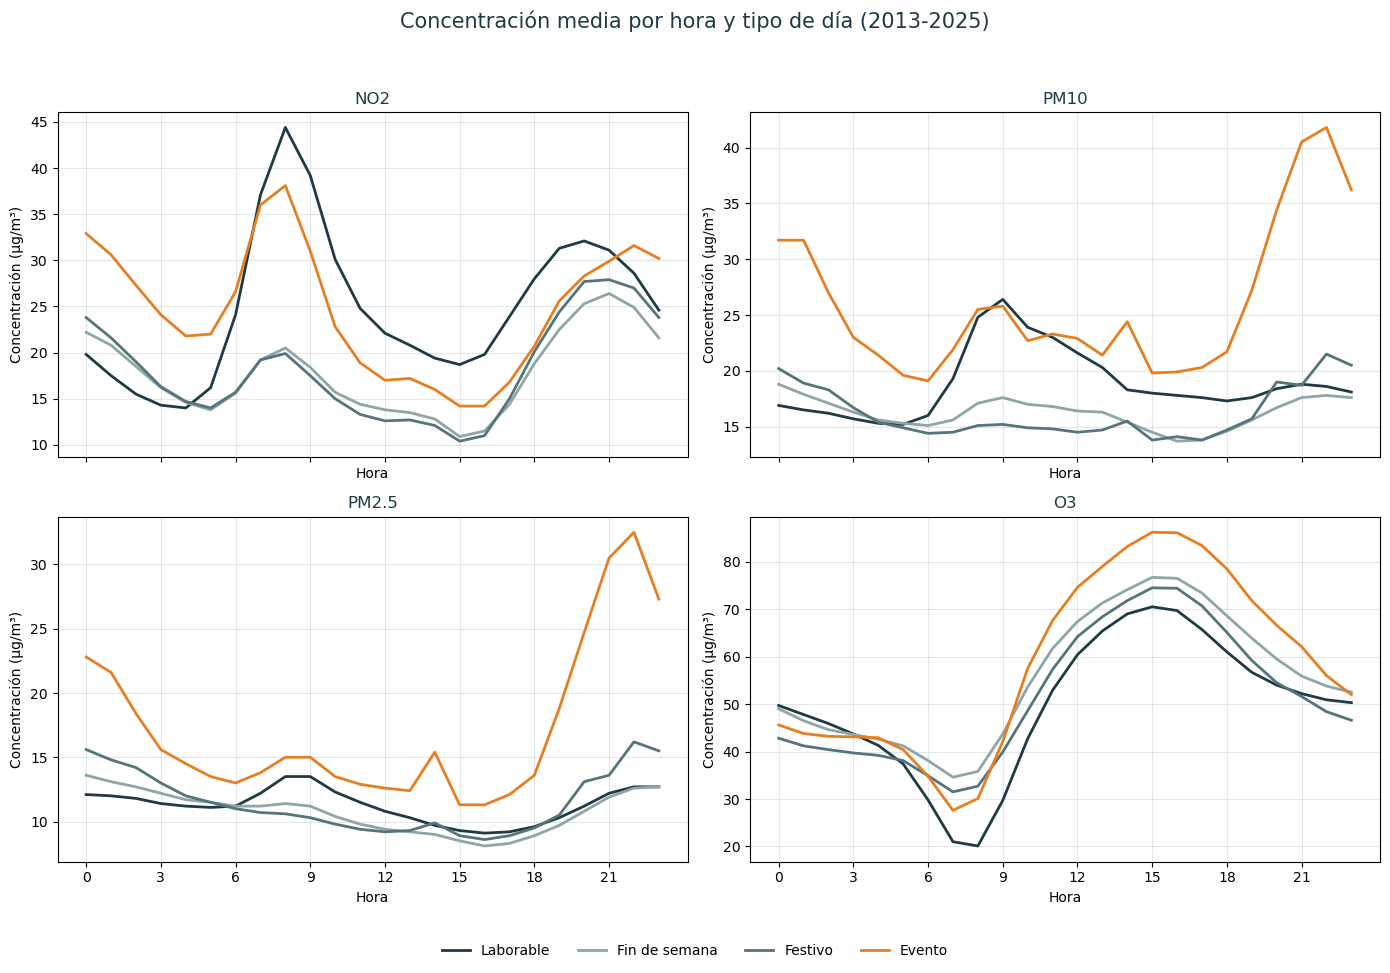

In [3]:
import matplotlib.pyplot as plt
import os

# Carpeta de salida
ruta = "/lakehouse/default/Files/export_graficos"
os.makedirs(ruta, exist_ok=True)

# Colores por tipo de día
colores = {
    "Laborable": "#203A43",
    "Fin de semana": "#8FA5A8",
    "Festivo": "#56747B",
    "Evento": "#E67E22"}

# Convertir a Pandas
datos = horario.toPandas()

# Crear figura 2x2
fig, ejes = plt.subplots(2, 2, figsize=(14, 9))

for eje, cont in zip(ejes.flat, ["NO2", "PM10", "PM2.5", "O3"]):

    for tipo in colores:
        d = datos[
            (datos["contaminante"] == cont) &
            (datos["tipo_dia"] == tipo)
        ].sort_values("hora")

        eje.plot(d["hora"],d["concentracion_promedio"],
            color=colores[tipo],linewidth=2,label=tipo)

    eje.set_title(cont, color="#203A43")
    eje.set_xlabel("Hora")
    eje.set_ylabel("Concentración (µg/m³)")
    eje.set_xticks(range(0, 24, 3))
    eje.grid(alpha=0.2)

# Leyenda común
fig.legend(*ejes[0, 0].get_legend_handles_labels(),
    loc="lower center",ncol=4)

fig.suptitle("Concentración media por hora y tipo de día (2013-2025)",
    color="#203A43")

plt.tight_layout(rect=[0, 0.06, 1, 0.96])

# Guardar PNG
plt.savefig(f"{ruta}/06_patron_horario.png",dpi=300,bbox_inches="tight")

plt.show()

Hablemos un poco de contaminantes para intentar hipotetizar el por qué de estas graficas
* **NO2:** Dióxido de nitrógeno. Proviene principalmente de los motores de los vehículos.
* **NO:** Monóxido de nitrógeno. Sale directamente del motor y en el aire se transforma en NO2.
* **PM10:** Partículas de menos de 10 micras. Polvo de calles y obras, frenos y neumáticos, sal marina, humo.
* **PM2.5** Partículas de menos de 2,5 micras. Combustión de motores, calefacciones, quemas, fuegos artificiales.
* **O3:** Ozono. No se emite directamente. Se forma en el aire por la presencia de otros contaminantes con la luz del sol. El NO consume el Ozono.

**Observaciones:**
- El NO2 presenta picos entre las 8 y 10 de la mañana en días laborables y un segundo pico entre las 20 y 21.
- En fines de semana y festivos el pico de la mañana de NO2 casi desaparece, aunque se mantiene el de la noche.
- PM10 y PM2.5 presentan un pico suave entre las 8 y 10 de la mañana en días laborables. 
- PM10 y PM2.5 registran picos desde las 20 hs hasta la madrugada en días de eventos.
- En días festivos y en fines de semana la concentración media de NO2, PM10 y PM2.5 es mas baja.
- El O3, contrario al NO2, tiene su mínimo entre las 7 y 8 de la mañana y su pico máximo a las 15.
- El O3 es más alto en fines de semana y festivos que en días laborables , y sobre todo, sube por encima del resto en días de eventos

### 3.1 ¿Qué pasa en los días de eventos?
En los días de eventos, notamos que PM10 y PM2.5 se elevan en su concentración durante la noche.

Analicemos esas fechas entendiendo si es en Fallas, por ejemplo,que es cuando hay mayor concentración de humo, fuegos artificiales, pólvora
¿Se viene repitiendo esto todos los años?
¿Va mejorando o empeora? 


In [4]:
#Fallas vs No Fallas

fallas = spark.sql("""
    WITH meses_fallas AS (
        SELECT DISTINCT anio, mes 
        FROM aire
        WHERE nombre_evento = 'Fallas'
    )

    SELECT
        a.anio,
        a.contaminante,
        ROUND(AVG(CASE when a.nombre_evento = 'Fallas' THEN a.concentracion END),1) AS fallas,
        ROUND(AVG(CASE when COALESCE(a.nombre_evento, '') <> 'Fallas' THEN a.concentracion END),1) AS resto_del_mes,
        ROUND(
            ( AVG(CASE WHEN a.nombre_evento = 'Fallas' THEN a.concentracion END)
            - AVG(CASE WHEN COALESCE(a.nombre_evento, '') <> 'Fallas' THEN a.concentracion END) )
            / AVG(CASE WHEN COALESCE(a.nombre_evento, '') <> 'Fallas' THEN a.concentracion END)
            * 100
        , 0) AS aumento_pct
    FROM aire a
    JOIN meses_fallas m ON a. anio = m.anio AND a.mes = m.mes
    WHERE a.hora between 20 AND 23
    AND a.contaminante IN ('NO2','PM10','PM2.5')
    GROUP BY a.anio, a.contaminante
    ORDER BY a.anio, a.contaminante
""")

display (fallas)

StatementMeta(, d728e202-fae7-4fe7-9e15-bffc4f86b016, 9, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, f3cac513-e8b8-4ca3-ad21-7912fd9cab18)

**Observaciones:**
- Durante las noches de Fallas (20 a 23 h), la concentración de partículas (PM10, PM2.5) supera la del resto de los meses en la mayoría de los años. 
- En 2024 y 2025 se registran los mayores aumentos: en 2025, un 229% en PM10 y un 392% en PM2.5.
- Con respecto al NO2, no se observa un efecto Fallas: unos años sube y otros años baja. 
- 2020 no aparece en el analisis porque ese año se supendieron las fallas.

Conclusión: el aumento de partículas se explica por la pirotecnia y la quema de monumentos. El NO2, que procede principalmente del tráfico, no aumenta, ya que durante las Fallas el tráfico se reduce por los cortes de calles.

StatementMeta(, d728e202-fae7-4fe7-9e15-bffc4f86b016, 127, Finished, Available, Finished, False)

Gráfico guardado correctamente:
/lakehouse/default/Files/export_graficos/06_fallas.png


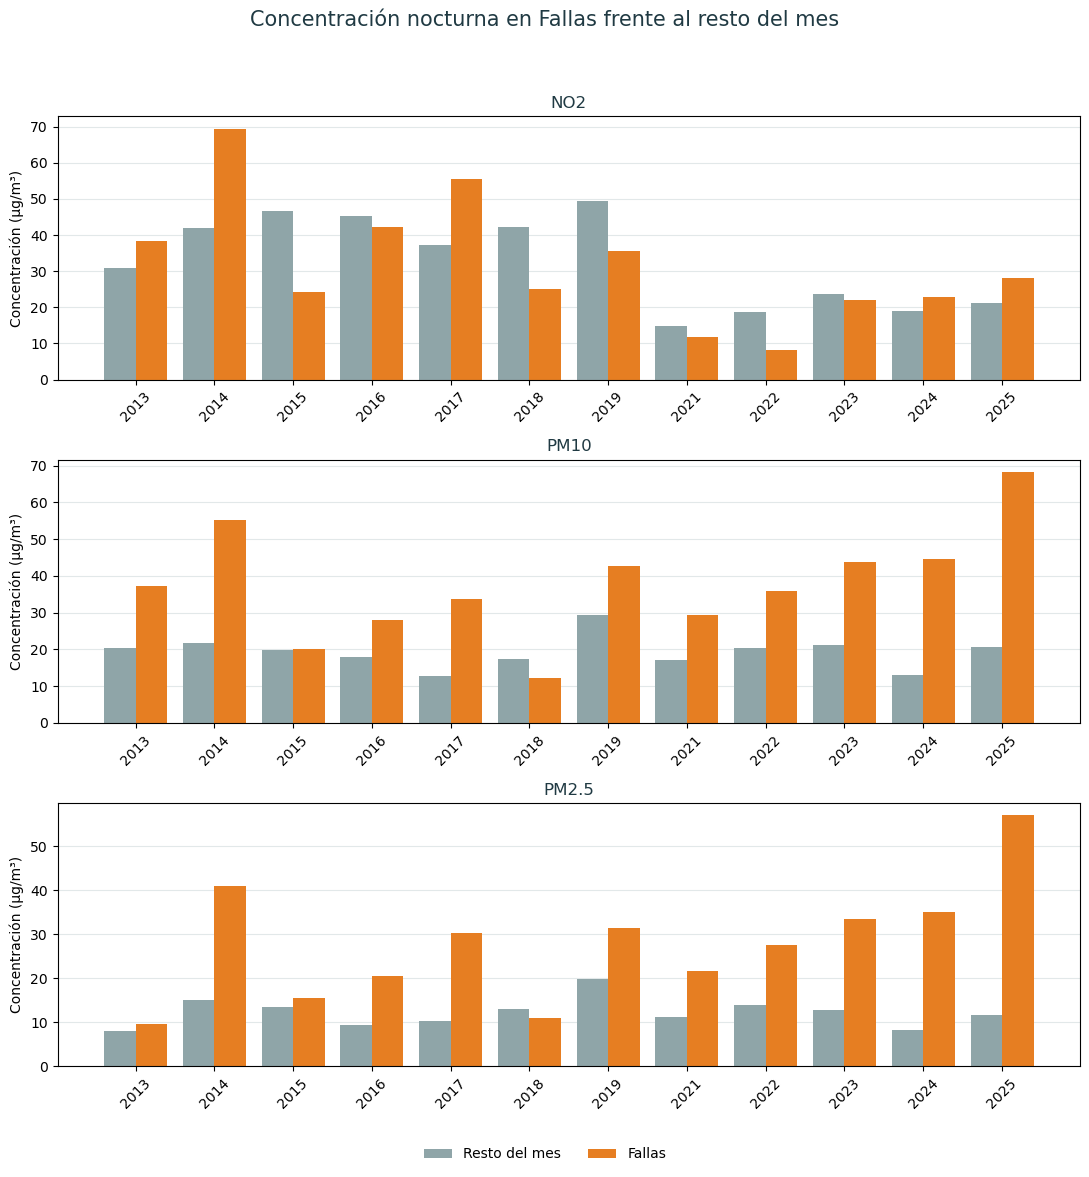

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import os

# Carpeta de salida
ruta = "/lakehouse/default/Files/export_graficos"
os.makedirs(ruta, exist_ok=True)

# Colores
azul = "#203A43"
gris = "#8FA5A8"
naranja = "#E67E22"

# Convertir a Pandas
datos = fallas.toPandas()

# Crear figura 3x1
fig, ejes = plt.subplots(3, 1, figsize=(11, 12))

for eje, cont in zip(ejes, ["NO2", "PM10", "PM2.5"]):

    d = datos[datos["contaminante"] == cont].sort_values("anio")
    x = np.arange(len(d))
    ancho = 0.4

    # Comparar Fallas con el resto del mes
    eje.bar(x - ancho/2, d["resto_del_mes"], ancho,
            color=gris, label="Resto del mes")

    eje.bar(x + ancho/2, d["fallas"], ancho,
            color=naranja, label="Fallas")

    eje.set_xticks(x)
    eje.set_xticklabels(d["anio"], rotation=45)
    eje.set_title(cont, color=azul)
    eje.set_ylabel("Concentración (µg/m³)")
    eje.grid(axis="y", alpha=0.2)
    eje.set_axisbelow(True)

# Leyenda común
fig.legend(*ejes[0].get_legend_handles_labels(),loc="lower center",ncol=2)
fig.suptitle("Concentración nocturna en Fallas frente al resto del mes",
    color=azul)

plt.tight_layout(rect=[0, 0.05, 1, 0.96])

# Guardar solo PNG
plt.savefig(f"{ruta}/06_fallas.png",dpi=300,bbox_inches="tight")

plt.show()

## 4. Patrón semanal para cada contaminante
¿Qué días de la semana tienen la concentración más alta y cuáles las mas bajas?

In [7]:
semanal = spark.sql("""
    SELECT
        contaminante,
        dia_semana,
        nombre_dia,
        ROUND(AVG(concentracion),1) AS concentracion_promedio
    FROM aire
    GROUP BY contaminante, dia_semana, nombre_dia 
    ORDER BY contaminante, dia_semana, nombre_dia
""")

display (semanal)

StatementMeta(, d728e202-fae7-4fe7-9e15-bffc4f86b016, 130, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, baa0fdcc-9957-4a9e-ab60-3cd0896ae5a5)

StatementMeta(, d728e202-fae7-4fe7-9e15-bffc4f86b016, 214, Finished, Available, Finished, False)

Variación porcentual del fin de semana respecto a laborables:
contaminante
NO2     -27.3
O3       11.1
PM10    -12.4
PM2.5    -3.4
Name: concentracion_promedio, dtype: float64
Gráfico guardado correctamente:
/lakehouse/default/Files/export_graficos/06_patron_semanal.png


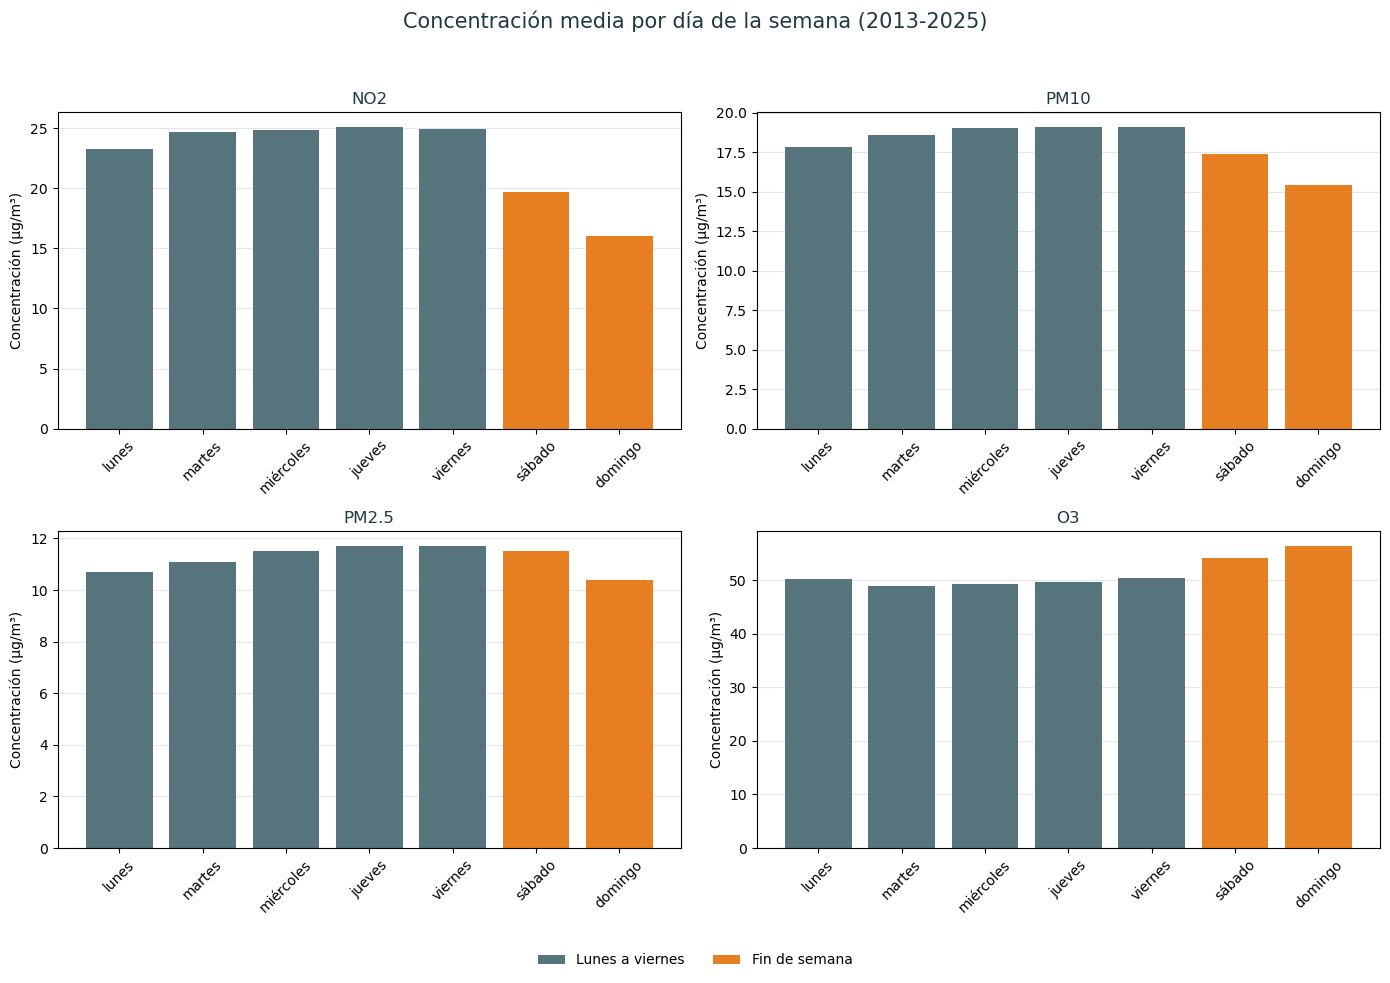

In [8]:
import matplotlib.pyplot as plt
import os

# Carpeta de salida
ruta = "/lakehouse/default/Files/export_graficos"
os.makedirs(ruta, exist_ok=True)

# Colores
azul = "#203A43"
gris = "#8FA5A8"
azul_gris = "#56747B"
naranja = "#E67E22"

# Convertir a Pandas
datos_semanal = semanal.toPandas()

# Comparar laborables y fines de semana
laborable = datos_semanal[datos_semanal["dia_semana"] <= 5].groupby("contaminante")["concentracion_promedio"].mean()
finde = datos_semanal[datos_semanal["dia_semana"] >= 6].groupby("contaminante")["concentracion_promedio"].mean()

comparacion = (((finde - laborable) / laborable) * 100).round(1)
print(comparacion)

# Crear figura 2x2
fig, ejes = plt.subplots(2, 2, figsize=(14, 9))

for eje, cont in zip(ejes.flat, ["NO2", "PM10", "PM2.5", "O3"]):

    d = datos_semanal[datos_semanal["contaminante"] == cont].sort_values("dia_semana")

    # Laborables en azul y fines de semana en naranja
    colores = [azul_gris if dia <= 5 else naranja for dia in d["dia_semana"]]

    eje.bar(d["nombre_dia"], d["concentracion_promedio"], color=colores)

    eje.set_title(cont, color=azul)
    eje.set_ylabel("Concentración (µg/m³)")
    eje.tick_params(axis="x", rotation=45)
    eje.grid(axis="y", alpha=0.2)
    eje.set_axisbelow(True)

fig.suptitle("Concentración media por día de la semana (2013-2025)", color=azul)
plt.tight_layout()

# Guardar solo PNG
plt.savefig(f"{ruta}/06_patron_semanal.png", dpi=300, bbox_inches="tight")
plt.show()

**Observaciones:**
- El NO2 es el contaminante que más cambia en su concentración dependiendo si es día laborable o fin de semana, disminuyendo alrededor del 27% durante el fin de semana. Esto se explica por la disminución de tráfico.
- PM10 disminuye un 12% durante el fin de semana, mientras que PM2.5 muestra un leve descenso (3%).
- El O3, por el contrario, muestra un aumento durante el fin de semana, cercano al 11%. Como explicamos anteriormente, el NO emitido por los vehículos consume el ozono. Con menos tráfico hay menos NO, por lo que es lógico que el O3 aumente el fin de semana.

Conclusión: el NO2 es el contaminante más ligado a la actividad semanal y al tráfico. La PM2.5 casi no varía, lo que indica que procede en gran parte de otras fuentes de contaminación y no sólo del tráfico local.

## 5. Estacionalidad mensual
¿En qué meses del año es más alta la concentracion de cada contaminante?

In [9]:
mensual = spark.sql("""
    SELECT
        contaminante,
        mes,
        nombre_mes,
        ROUND(AVG(concentracion),1) AS concentracion_promedio
    FROM aire
    GROUP BY contaminante, mes, nombre_mes 
    ORDER BY contaminante, mes, nombre_mes
""")

display (mensual)

StatementMeta(, d728e202-fae7-4fe7-9e15-bffc4f86b016, 216, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, f2c41511-5b9e-49af-9ba6-639179c82f0a)

In [10]:
datos_mensual = mensual.toPandas()

# Media por estacion, por contaminante
invierno = datos_mensual[datos_mensual["mes"].isin ([12,1,2])].groupby("contaminante")["concentracion_promedio"].mean()
verano = datos_mensual[datos_mensual["mes"].isin ([6,7,8])].groupby("contaminante")["concentracion_promedio"].mean()



comparacion = (((invierno - verano) / verano) * 100).round(1)
print(comparacion)

StatementMeta(, d728e202-fae7-4fe7-9e15-bffc4f86b016, 218, Finished, Available, Finished, False)

contaminante
NO2      75.4
O3      -43.4
PM10      9.7
PM2.5    13.8
Name: concentracion_promedio, dtype: float64


**Observaciones:**
- En NO2 presenta una fuerte estacionalidad: en invierno (diciembre a febrero) su concentración media es un 75% mayor que en verano (junio a agosto). 
- El O3 muestra el comportamiento opuesto: en invierno es un 43% menor que en verano, ya que su formación depende de la radiación solar y la temperatura.
- PM10 y M2.5 tienen una estacionalidad mas suaves con concentraciones entre aproximadamente un 9% y 13% mayor en invierno que en verano
-La variación estacional del NO2 (75%) es mucho mayor que la semanal (27%), lo que sugiere que hay otro factor con un peso más importante que explica esta concentración.



A partir de un análisis de fuentes, encontramos que estas variaciones se explican por **meteorología**, más que por tráfico

**Malley et al.(2018):** una menor altura de la capa límite y las inversiones térmicas durante el invierno impiden que la contaminación, incluido en NO2, se ventile fuera de la capa límite provocando una mayor concentración en invierno en las ciudades europeas

**Rowland(2024):** muestra los mismos patrones en las concentraciones de NO2, PM2.5 y PM10 en otras ciudades europeas como Cracovia, Parías y Milan durante el invierno. Asímismo la concentración de O3 fue más alta en verano.


Malley, C. S. et al. (2018). Analysis of the distributions of hourly NO2 concentrations contributing to annual average NO2 concentrations across the European monitoring network between 2000 and 2014. Atmospheric Chemistry and Physics, 18, 3563–3587. https://doi.org/10.5194/acp-18-3563-2018

Rowland, O. E. (2024). Comparative analysis of meteorological parameters and their relationship with NO2, PM10, PM2.5 and O3 concentrations at selected urban air quality monitoring stations in Krakow, Paris, and Milan. Discover Environment, 2, 75. https://doi.org/10.1007/s44274-024-00060-2 

StatementMeta(, d728e202-fae7-4fe7-9e15-bffc4f86b016, 351, Finished, Available, Finished, False)

Gráfico guardado correctamente:
/lakehouse/default/Files/export_graficos/06_estacionalidad.png


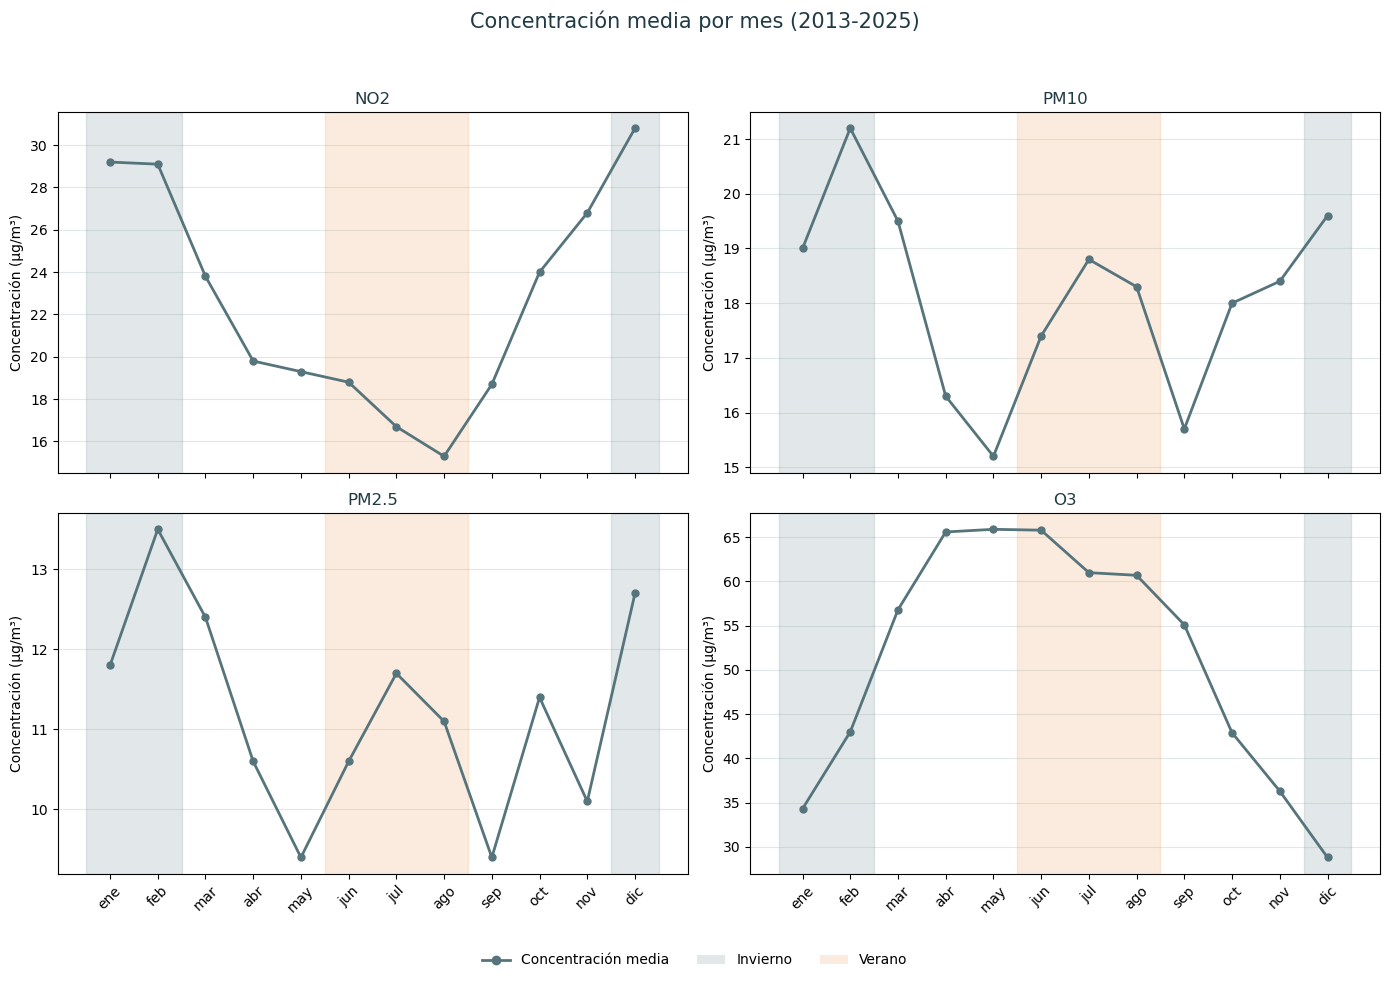

In [11]:
import matplotlib.pyplot as plt
import os

# Carpeta de salida
ruta = "/lakehouse/default/Files/export_graficos"
os.makedirs(ruta, exist_ok=True)

# Colores
azul = "#203A43"
gris = "#8FA5A8"
azul_gris = "#56747B"
naranja = "#E67E22"

meses = ["ene", "feb", "mar", "abr", "may", "jun",
         "jul", "ago", "sep", "oct", "nov", "dic"]

# Crear figura 2x2
fig, ejes = plt.subplots(2, 2, figsize=(14, 9))

for eje, cont in zip(ejes.flat, ["NO2", "PM10", "PM2.5", "O3"]):

    d = datos_mensual[datos_mensual["contaminante"] == cont].sort_values("mes")

    # Franjas de invierno
    eje.axvspan(0.5, 2.5, color=gris, alpha=0.25)
    eje.axvspan(11.5, 12.5, color=gris, alpha=0.25)

    # Franja de verano
    eje.axvspan(5.5, 8.5, color=naranja, alpha=0.15)

    # Concentración mensual
    eje.plot(d["mes"],d["concentracion_promedio"],
        color=azul_gris,marker="o",linewidth=2)

    eje.set_title(cont, color=azul)
    eje.set_ylabel("Concentración (µg/m³)")
    eje.set_xticks(range(1, 13))
    eje.set_xticklabels(meses, rotation=45)
    eje.grid(axis="y", alpha=0.2)

fig.suptitle("Concentración media por mes (2013-2025)",
    color=azul)

plt.tight_layout()

# Guardar PNG
plt.savefig(f"{ruta}/06_estacionalidad.png",dpi=300,bbox_inches="tight")

plt.show()

- El NO2 presenta una forma de U: máximo en diciembre y enero, mínimo en agosto, mes en que coinciden las condiciones de verano y la reducción del tráfico por vacaciones.
- El O3 alcanza su máximo entre abril y junio, antes del pleno verano.
- Las partículas presentan dos picos: uno en invierno (febrero) y otro en verano (julio). En nuestra investigación de fuentes, se indica que una posible causa de esto ultimo es el polvo sahariano

## 6. Evolución anual
¿Cómo ha evolución la concentración de cada contaminante entre 2013 y 2025?
¿Hay años que no siguen la tendencia?
¿Hay años que marcan una tendencia?

In [4]:
anual = spark.sql("""
    SELECT
        contaminante,
        anio,
        ROUND(AVG(concentracion),1) AS concentracion_promedio
    FROM aire
    GROUP BY contaminante, anio
    ORDER BY contaminante, anio
""")

display (anual)

StatementMeta(, 59fe2443-8789-4259-aa62-c256520dc862, 36, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, c199d1ca-af46-4dfe-b028-171f7380e4da)

In [5]:
datos_anual = anual.toPandas()

#Comparamos año inicial y año final de datos
anio_2013 = datos_anual[datos_anual["anio"] == 2013].groupby("contaminante")["concentracion_promedio"].mean()
anio_2025 = datos_anual[datos_anual["anio"] == 2025].groupby("contaminante")["concentracion_promedio"].mean()

#Comparamos periodos de 3 años
anio_2013_2015 = datos_anual[datos_anual["anio"].isin([2013, 2014, 2015])].groupby("contaminante")["concentracion_promedio"].mean()
anio_2023_2025 = datos_anual[datos_anual["anio"].isin([2023, 2024, 2025])].groupby("contaminante")["concentracion_promedio"].mean()


comparacion_2013_2025 = (((anio_2025 - anio_2013) / anio_2013) * 100).round(1)
print(comparacion_2013_2025)

comparacion_trianual = (((anio_2023_2025 - anio_2013_2015) / anio_2013_2015) * 100).round(1)
print(comparacion_trianual)

StatementMeta(, 59fe2443-8789-4259-aa62-c256520dc862, 37, Finished, Available, Finished, False)

contaminante
NO2     -49.5
O3       10.0
PM10     31.7
PM2.5    11.2
Name: concentracion_promedio, dtype: float64
contaminante
NO2     -46.8
O3        7.1
PM10      9.0
PM2.5   -12.2
Name: concentracion_promedio, dtype: float64


**Observaciones:**
Se realizaron dos análisis: 
- Año inicial de datos vs año final de datos (2025 vs 2023):  Se observa que NO2 baja casi un 50%, mientras que los otros contaminantes suben desde un 10% hasta un 31%
- Analisis trianual (2013-2015 vs 2023-2025) : la tendencia del NO2 se puede afirmar ya que este analisis tambien demuestra una disminucion cercana al 45%. Por el otro lado, Se ven patrones diferentes en PM10 y PM2.5. PM10 ha aumentado pero no en un 30% sino en un 9%. El PM2.5 tambien ha disminuido.

Hacer análisis de un sólo año puede llevarnos a conclusiones equivocadas porque un año en particular puede ser un año excepcional. Al realizar comparaciones de valores medios entre varios años, esa excepcionalidad se reduce.

Conclusiones:
- La tendencia del NO2, es similar a lo que se observa en otros países de Europa, y está muy relacionada a los vehículos híbrido y a normativas de emisiones más exigentes.
- El PM2.5 ha descendido cerca de un 12%
- El PM 10 ha aumentado cerca del 10%. Este cambio podria deberse a factores climaticos como mayores episodios de viento sahariano en los ultimos años
- El O3 aumenta un 7%, coherente con la reducción del NO2.


StatementMeta(, 59fe2443-8789-4259-aa62-c256520dc862, 38, Finished, Available, Finished, False)

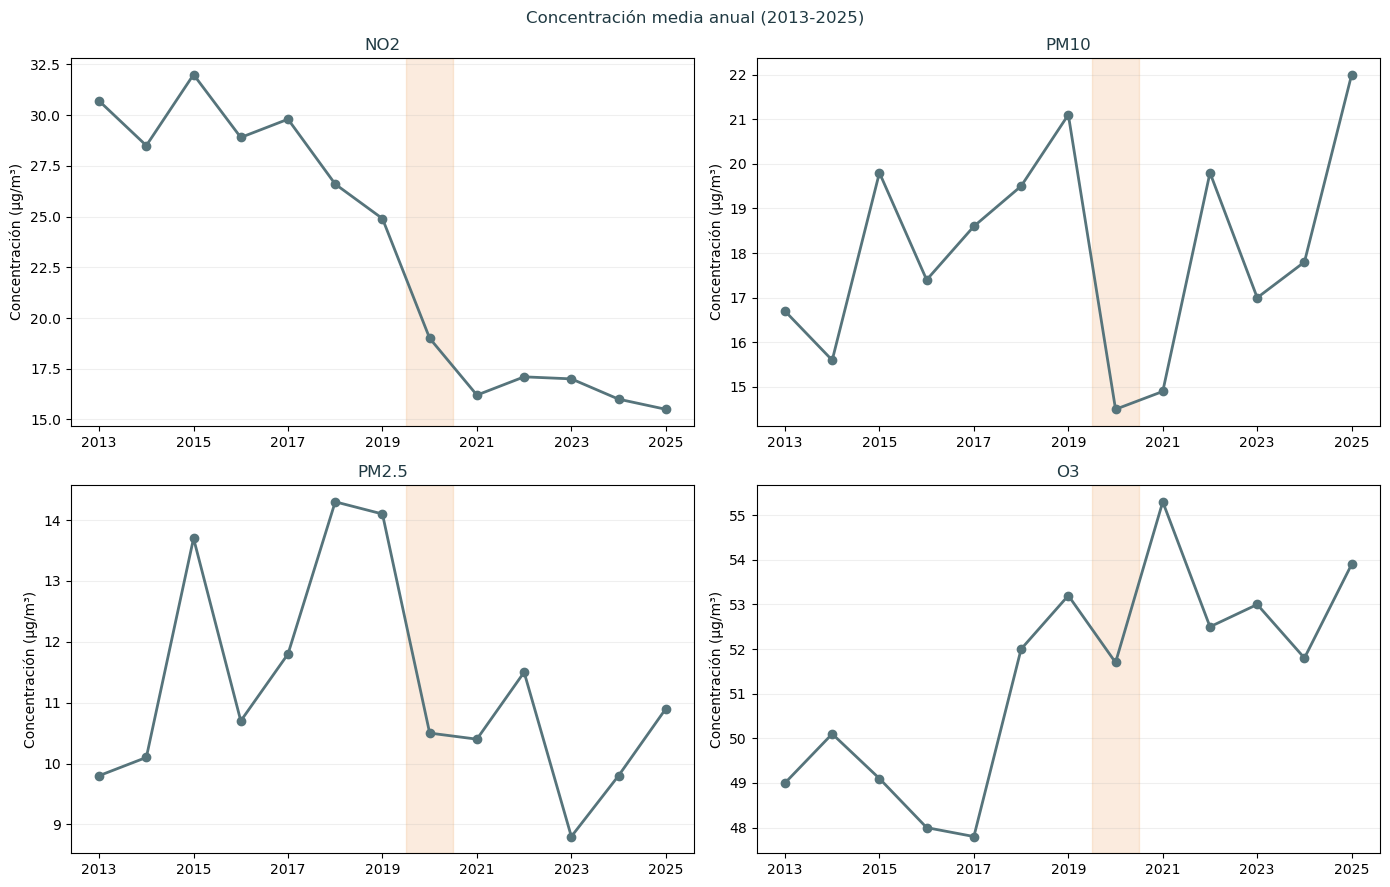

In [6]:
import matplotlib.pyplot as plt
import os

# Carpeta de salida
ruta = "/lakehouse/default/Files/export_graficos"
os.makedirs(ruta, exist_ok=True)

# Colores
azul = "#203A43"
gris = "#8FA5A8"
azul_gris = "#56747B"
naranja = "#E67E22"

# Crear figura 2x2
fig, ejes = plt.subplots(2, 2, figsize=(14, 9))

for eje, cont in zip(ejes.flat, ["NO2", "PM10", "PM2.5", "O3"]):
    
    d = datos_anual[datos_anual["contaminante"] == cont].sort_values("anio")
    
    # Línea de evolución
    eje.plot(d["anio"],d["concentracion_promedio"],
        color=azul_gris,marker="o",linewidth=2)

    # Resaltar 2020
    eje.axvspan(2019.5, 2020.5, color=naranja, alpha=0.15)

    eje.set_title(cont, color=azul)
    eje.set_ylabel("Concentración (µg/m³)")
    eje.set_xticks(range(2013, 2026, 2))
    eje.grid(axis="y", alpha=0.2)

fig.suptitle("Concentración media anual (2013-2025)", color=azul)
plt.tight_layout()

# Guardar PNG
plt.savefig(f"{ruta}/06_evolucion_anual.png", dpi=300, bbox_inches="tight")
plt.show()

**Observaciones:**
- El NO2 ya mostraba una tendencia decreciente desde 2017, pero en 2020 se produce un descenso marcado (de unos 25 a 19 µg/m³). Además, no recupera los niveles anteriores: desde 2021 se mantiene en torno a 16 µg/m³, la mitad que en 2013.
- La PM10 alcanza en 2020 su valor más bajo de toda la serie y la PM2.5 también desciende de forma notable ese año. En ambos casos, las concentraciones vuelven a aumentar en los años siguientes. La PM2.5 registra su mínimo en 2023.
- El O3 no muestra un cambio destacado en 2020 en la media anual. Su valor más alto se registra en 2021.

**¿Qué ocurrió en 2020?** El descenso del NO2, el contaminante más ligado al tráfico, y de las partículas sugiere una reducción excepcional de la actividad ese año posiblemente debido a la pandemia. Analizaremos posteriormente ese comportamiento en los meses de ese año para verificar nuestra teoría.

## 7. El 2020 en detalle
¿En qué mes se produjo la caída?

In [1]:
meses_2020 = spark.sql("""
    SELECT contaminante,
           mes,
           ROUND(AVG(CASE WHEN anio = 2020 THEN concentracion END), 1)               AS media_2020,
           ROUND(AVG(CASE WHEN anio BETWEEN 2017 AND 2019 THEN concentracion END), 1) AS media_2017_2019,
           ROUND(
               ( AVG(CASE WHEN anio = 2020 THEN concentracion END)
               - AVG(CASE WHEN anio BETWEEN 2017 AND 2019 THEN concentracion END) )
               / AVG(CASE WHEN anio BETWEEN 2017 AND 2019 THEN concentracion END)
               * 100
           , 1) AS cambio_pct
    FROM aire
    WHERE anio BETWEEN 2017 AND 2020
    GROUP BY contaminante, mes
    ORDER BY contaminante, mes
""")

display(meses_2020)

StatementMeta(, 59fe2443-8789-4259-aa62-c256520dc862, 3, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, f0cac28e-9481-47a1-8396-169123439d1d)

**Observaciones:**
Comparando la media de 2017-2019 con la media de 2020 por cada mes, podemos afirmar que la pandemia fue la causa de la caída de NO2.
Los datos muestran que entre Marzo a Junio, meses de confinamiento, el descenso del NO2 fue entre un 50% a 65%



StatementMeta(, 59fe2443-8789-4259-aa62-c256520dc862, 18, Finished, Available, Finished, False)

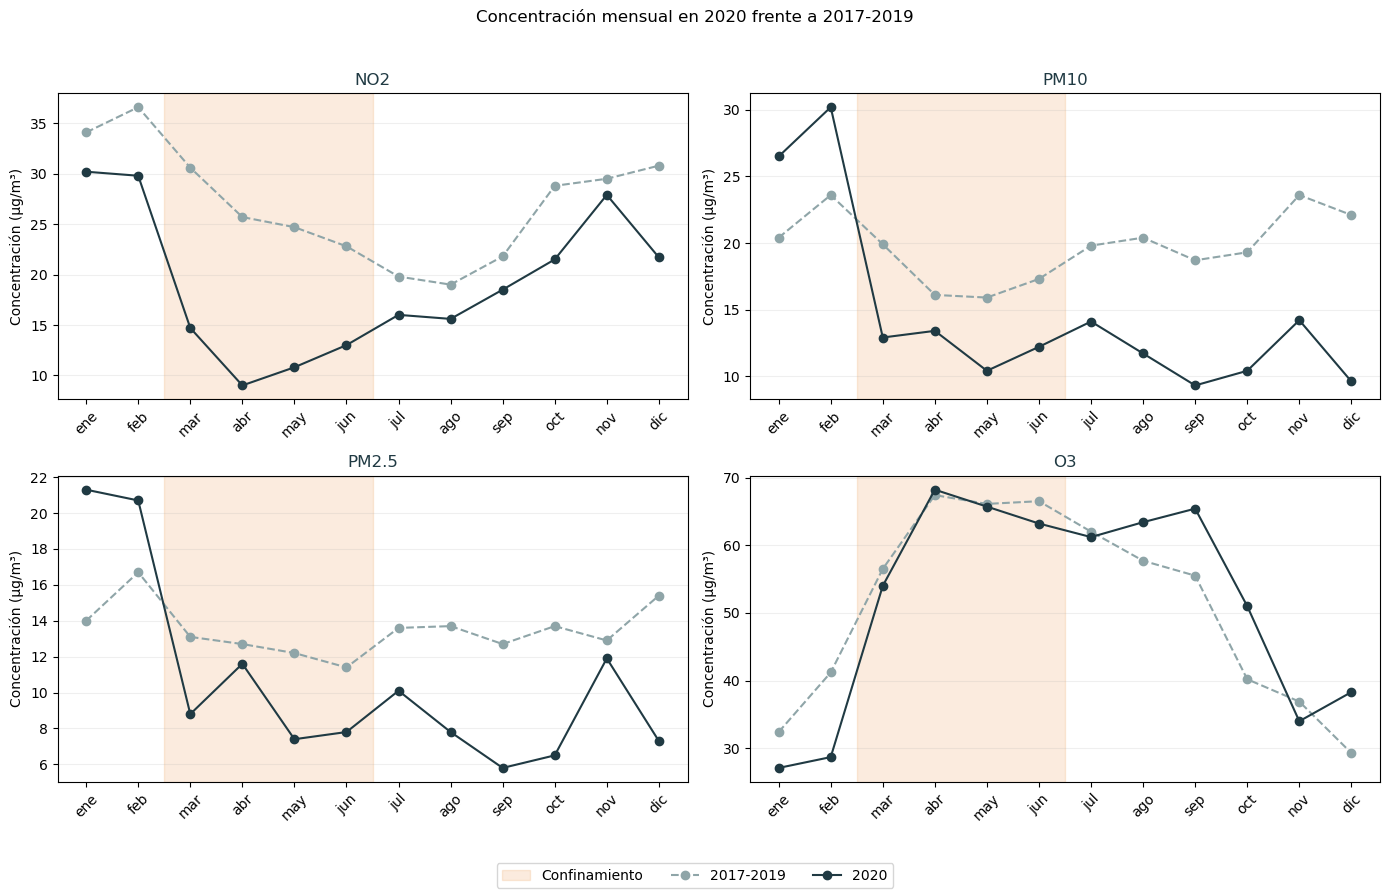

In [2]:
import matplotlib.pyplot as plt
import os

# Carpeta de salida
ruta = "/lakehouse/default/Files/export_graficos"
os.makedirs(ruta, exist_ok=True)

# Convertir a Pandas
datos = meses_2020.toPandas()

meses = ["ene", "feb", "mar", "abr", "may", "jun",
         "jul", "ago", "sep", "oct", "nov", "dic"]

# Crear gráficos 2x2
fig, ejes = plt.subplots(2, 2, figsize=(14, 9))

for eje, cont in zip(ejes.flat, ["NO2", "PM10", "PM2.5", "O3"]):

    d = datos[datos["contaminante"] == cont].sort_values("mes")

    # Período de confinamiento
    eje.axvspan(2.5, 6.5, color="#E67E22", alpha=0.15,
                label="Confinamiento")

    # Comparación de concentraciones
    eje.plot(d["mes"], d["media_2017_2019"],
             color="#8FA5A8", linestyle="--",
             marker="o", label="2017-2019")

    eje.plot(d["mes"], d["media_2020"],
             color="#203A43", marker="o", label="2020")

    eje.set_xticks(range(1, 13))
    eje.set_xticklabels(meses, rotation=45)
    eje.set_title(cont, color="#203A43")
    eje.set_ylabel("Concentración (µg/m³)")
    eje.grid(axis="y", alpha=0.2)

# Leyenda única
fig.legend(*ejes[0, 0].get_legend_handles_labels(),
           loc="lower center", ncol=3)

fig.suptitle("Concentración mensual en 2020 frente a 2017-2019")
plt.tight_layout(rect=[0, 0.06, 1, 0.96])

# Guardar PNG
plt.savefig(f"{ruta}/06_confinamiento.png",
            dpi=300, bbox_inches="tight")

plt.show()

**Observaciones:**
- El NO2 luego del confinamiento sigue una forma similar a la de años anteriores, pero sin recuperar sus valores: se mantiene siempre por debajo.
- El O3 sigue en 2020 la misma evolución estacional que en 2017-2019, con valores muy similares durante el confinamiento. No se observa un efecto claro del confinamiento sobre el ozono.
- PM10 y PM2.5 comienzan 2020 con valores más altos que en años anteriores y caen a partir de marzo. Sin embargo, no se recuperan al terminar el confinamiento: se mantienen bajas el resto del año e incluso alcanzan sus valores mínimos en septiembre. Por ello, el descenso de las partículas en 2020 no puede atribuirse solo al confinamiento.

Conclusión: el NO2 es el contaminante que mejor refleja la reducción del tráfico durante el confinamiento.

## 8. Patrones espaciales


In [4]:
spark.sql ("USE gold")

DataFrame[]

In [7]:
cobertura = spark.sql("""
    SELECT nombre_estacion,
           tipo_estacion,
           distrito,
           contaminante,
           MIN(anio) AS desde,
           MAX(anio) AS hasta,
           COUNT(*)  AS mediciones
    FROM aire
    GROUP BY nombre_estacion, tipo_estacion, distrito, contaminante
    ORDER BY nombre_estacion, contaminante
""")

cobertura.toPandas()

,nombre_estacion,tipo_estacion,distrito,contaminante,desde,hasta,mediciones
0,ALBUFERA,Fondo,POBLATS DEL SUD,NO2,2014,2014,4279
1,ALBUFERA,Fondo,POBLATS DEL SUD,O3,2014,2014,4465
2,AVD. FRANCIA,Tráfico,CAMINS AL GRAU,NO2,2013,2025,106171
3,AVD. FRANCIA,Tráfico,CAMINS AL GRAU,O3,2013,2025,109639
4,AVD. FRANCIA,Tráfico,CAMINS AL GRAU,PM10,2017,2025,69998
5,AVD. FRANCIA,Tráfico,CAMINS AL GRAU,PM2.5,2017,2025,69824
6,BULEVARD SUD,Tráfico,JESUS,NO2,2013,2025,105810
7,BULEVARD SUD,Tráfico,JESUS,O3,2013,2025,107967
8,CENTRE,Tráfico,QUATRE CARRERES,NO2,2019,2025,59804
9,CENTRE,Tráfico,QUATRE CARRERES,PM10,2021,2025,41303


Para comparar las estaciones usamos el período 2021-2025, el único en el que todas tienen datos. Dejamos afuer Albufera, que sólo tiene datos de 2014.
No todas las estaciones miden los cuatro contaminantes: CENTRE no mide =3 y BULEVARD SUD y VIVERS sólo miden NO2 y O3.

In [9]:
# Media por contaminante por estación (2021 -2025)

por_estacion = spark.sql ("""
    SELECT nombre_estacion,
            tipo_estacion,
            contaminante,
            ROUND(AVG(concentracion), 1) AS concentracion_media
    FROM aire
    WHERE anio BETWEEN 2021 AND 2025
        AND nombre_estacion <> 'ALBUFERA'
    GROUP BY nombre_estacion, tipo_estacion, contaminante
    ORDER BY contaminante, concentracion_media DESC
""")

por_estacion.toPandas()

,nombre_estacion,tipo_estacion,contaminante,concentracion_media
0,CENTRE,Tráfico,NO2,20.5
1,BULEVARD SUD,Tráfico,NO2,19.2
2,PISTA DE SILLA,Tráfico,NO2,18.1
3,MOLÍ DEL SOL,Tráfico,NO2,15.5
4,VIVERS,Fondo,NO2,15.4
5,AVD. FRANCIA,Tráfico,NO2,14.2
6,POLITÈCNIC,Fondo,NO2,11.5
7,VIVERS,Fondo,O3,56.5
8,MOLÍ DEL SOL,Tráfico,O3,54.1
9,POLITÈCNIC,Fondo,O3,53.9


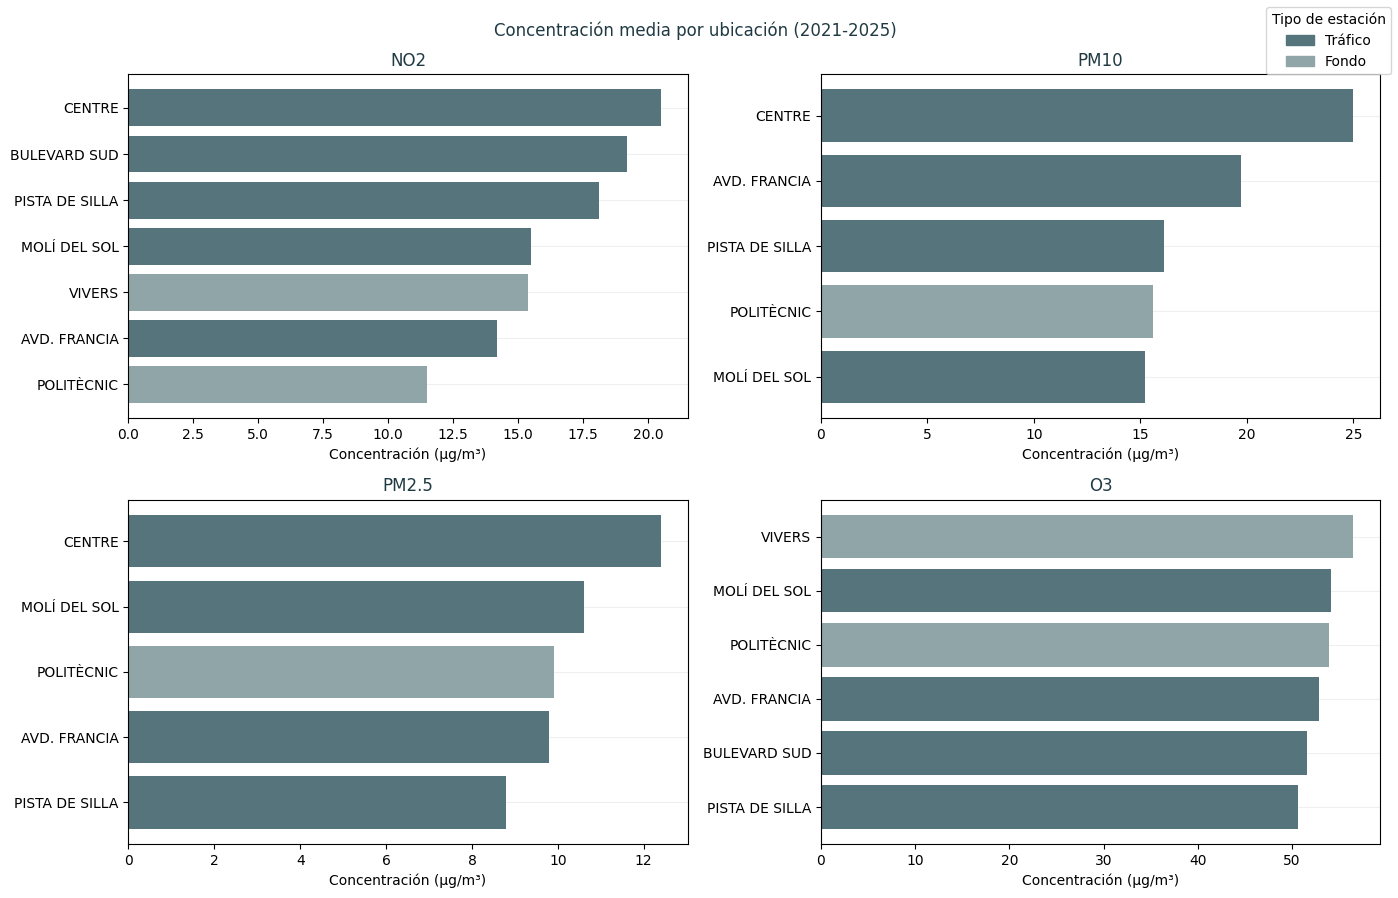

In [20]:
import matplotlib.pyplot as plt
import os
from matplotlib.patches import Patch


# Carpeta de salida
ruta = "/lakehouse/default/Files/export_graficos"
os.makedirs(ruta, exist_ok=True)

# Colores
azul = "#203A43"
gris = "#8FA5A8"
azul_gris = "#56747B"
naranja = "#E67E22"

# Convertir a Pandas
datos_por_estacion = por_estacion.toPandas()

# Crear figura 2x2
fig, ejes = plt.subplots(2, 2, figsize=(14, 9))

for eje, cont in zip(ejes.flat, ["NO2", "PM10", "PM2.5", "O3"]):

    d = datos_por_estacion[datos_por_estacion["contaminante"] == cont].sort_values("concentracion_media")

    # Trafico y Fondo con distintos colores
    colores = [azul_gris if t == "Tráfico" else gris for t in d["tipo_estacion"]]

    eje.barh(d["nombre_estacion"] ,d["concentracion_media"],  color=colores)

    eje.set_title(cont, color=azul)
    eje.set_xlabel("Concentración (µg/m³)")
    eje.tick_params(axis="x")
    eje.grid(axis="y", alpha=0.2)
    eje.set_axisbelow(True)
   
leyenda = [Patch(color=azul_gris, label="Tráfico"),
           Patch(color=gris, label="Fondo")]
fig.legend(handles=leyenda, loc="upper right", title="Tipo de estación")

fig.suptitle("Concentración media por ubicación (2021-2025)", color=azul)
plt.tight_layout()

# Guardar solo PNG
plt.savefig(f"{ruta}/06_patron_espacial.png", dpi=300, bbox_inches="tight")
plt.show()

**Conclusiones:**
- CENTRE es la estación con mayor concentración de NO2, PM10 y PM2.5. No mide O3
- El NO2 es el contaminante con más diferencia entre estaciones: ejemplo: CENTRE casi duplica a POLITECNIC (20.5 µg/m³ vs 11.5 µg/m³).
- Las estaciones de tráfico suelen tener más NO2 que las de fondo, aunque VIVERS supera a AVD. FRANCIA .
- El O3 se comporta al revés que NO2: PISTA DE SILLA y BULEVARD SUD tienen mucho NO2 y bajo O3. VIVERS, lo contrario

## 9. Conclusiones

El análisis temporal muestra que la calidad del aire en Valencia responde a tres factores principales: el tráfico, la meteorología y eventos puntuales como las Fallas.

**1. El NO2 es el contaminante más ligado al tráfico.**
- Presenta picos a las 8-10 h y a las 20-21 h en días laborables, que casi desaparecen en fines de semana y festivos.
- El fin de semana su concentración es un 27 % menor que en días laborables.
- Durante el confinamiento de 2020 cayó entre un 43 % y un 65 % respecto a los mismos meses de 2017-2019, con el mayor descenso en abril.

**2. La meteorología explica gran parte de la variación estacional.**
- El NO2 es un 75 % mayor en invierno que en verano, una variación mucho mayor que la semanal (27 %). Las inversiones térmicas y la menor altura de la capa de mezcla dificultan la dispersión en invierno (Malley et al., 2018).
- El O3 se comporta al revés: es un 43 % menor en invierno, porque su formación depende de la radiación solar.
- Estos patrones coinciden con los observados en otras ciudades europeas (Rowland, 2024).

**3. El ozono responde de forma opuesta al NO2.**
- Su mínimo diario coincide con el pico de NO2 (7-8 h), y es un 11 % más alto el fin de semana. Con menos tráfico hay menos NO que lo consuma.
- A largo plazo, mientras el NO2 baja, el O3 aumenta un 7 %.

**4. Las partículas tienen un origen más variado.**
- Varían poco entre días laborables y fines de semana (PM2.5: -3 %), lo que indica que proceden en gran parte de fuentes distintas del tráfico local.
- Las Fallas provocan los mayores aumentos de la serie: en las noches de Fallas, la PM2.5 supera la del resto del mes en 11 de 12 años, con un aumento del 392 % en 2025.
- Su descenso en 2020 no se explica solo por el confinamiento, ya que se mantiene bajo el resto del año.

**5. Evolución 2013-2025.**
- El NO2 se ha reducido un 47 % (promedio 2013-2015 frente a 2023-2025) y no recuperó los niveles previos a 2020.
- La PM2.5 desciende un 12 %, la PM10 aumenta un 9 % y el O3 un 7 %.

**Implicaciones para el TFM:**
- El confinamiento es un experimento natural que cuantifica el efecto de una reducción drástica del tráfico sobre el NO2. Este dato servirá como referencia para los escenarios de predicción hacia 2030.
- Para el NO2 y el O3, las medidas sobre el tráfico tienen un efecto directo. 
- La meteorología condiciona las concentraciones, por lo que los modelos de predicción deberán incluir variables meteorológicas.
